# P02: Clasificación de la informalidad laboral en México con la ENOE 2T-2026.

---
Nombres:\
**Claudio Alejo Encarnación Martínez (750597)** \
**Alan Jesús Hernández Soto (752714)** 

Carrera: **Ingeniería Financiera** \
Materia: **Laboratorio de Aprendizaje Estadístico** \
Tipo de Trabajo: **Proyecto**

---

## 1. Objetivos

### 1.1 Objetivo general

Construir y comparar tres modelos de clasificación supervisada (regresión logística con regularización, máquina de vectores de soporte con kernel RBF y perceptrón multicapa), cuyos hiperparámetros se optimizan mediante optimización bayesiana con procesos gaussianos, para clasificar si una persona ocupada en México tiene un empleo informal a partir de los microdatos de la ENOE del segundo trimestre de 2026. El trabajo final permite estimar informalidad laboral y desarrollar perfiles en zonas o municipios para un posible desarrollo de nuevas políticas, programas o aciones focalizadas.

### 1.2 Objetivos específicos

1. Depurar y transformar los microdatos sociodemográficos de la ENOE 2T-2026 (tabla SDEM) para construir tres conjuntos de datos de distinta escala geográfica (Área Metropolitana de Guadalajara con 5 municipios, Jalisco y nacional), documentando y justificando cada decisión de limpieza.
2. Realizar un análisis exploratorio que identifique las variables más asociadas con la informalidad, así como problemas potenciales en los datos (redundancia, baja varianza y variables que funcionan casi como la variable objetivo).
3. Diseñar un pipeline de preprocesamiento reproducible (imputación, escalamiento y codificación OneHot) que se ajuste dentro de cada fold.
4. Optimizar los hiperparámetros de cada modelo con Optuna, maximizando el ROC-AUC promedio de una validación cruzada estratificada de 5 folds.
5. Comparar los modelos optimizados mediante la media y la desviación estándar del ROC-AUC en una validación cruzada de 10 folds, y verificar su desempeño en un conjunto de prueba independiente.
6. Evaluar si el desempeño y el modelo ganador se mantienen al pasar de la AMG a Jalisco y al conjunto nacional.
7. Interpretar los coeficientes de la regresión logística para identificar qué características se asocian con mayor o menor probabilidad de informalidad.

## 2. Marco teórico

### 2.1 Regresión logística

La regresión logística es un modelo para respuestas cualitativas. En lugar de predecir directamente la clase, modela la probabilidad de que una observación pertenezca a la clase positiva ($y=1$, empleo informal) aplicando la función sigmoide a una combinación lineal de los predictores:

$$ p(\mathbf{x}) = P(y=1 \mid \mathbf{x}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}} $$

Esto equivale a un modelo lineal en el *logit* (logaritmo de los momios):

$$ \ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p $$

Por eso $e^{\beta_j}$ se interpreta como una **razón de momios**: cuánto se multiplican los momios de ser informal cuando $x_j$ aumenta una unidad y lo demás se mantiene fijo.

Los coeficientes se estiman por máxima verosimilitud, lo que equivale a minimizar la función de costo de entropía cruzada (*log-loss*):

$$ J(\boldsymbol{\beta}) = -\sum_{i=1}^{n} \left[ y_i \ln(\hat{p}_i) + (1-y_i)\ln(1-\hat{p}_i) \right] $$

Esta función es **convexa**: cualquier mínimo local es global, así que el resultado no depende de la inicialización.

**Regularización.** Para controlar el sobreajuste y la colinealidad se agrega una penalización sobre los coeficientes. La forma general que usa `scikit-learn` (red elástica) es:

$$ \min_{\boldsymbol{\beta}} \; C \sum_{i=1}^{n} \ell(y_i, \hat{p}_i) + \frac{1-\rho}{2}\lVert\boldsymbol{\beta}\rVert_2^2 + \rho\lVert\boldsymbol{\beta}\rVert_1 $$

- $C$ es el **inverso** de la fuerza de regularización: un $C$ pequeño penaliza más y un $C$ grande se acerca a la regresión sin penalizar.
- $\rho$ (`l1_ratio`) mezcla las penalizaciones: $\rho=0$ es Ridge (L2, encoge todos los coeficientes), $\rho=1$ es Lasso (L1, puede volver exactamente cero algunos coeficientes, es decir, hace selección de variables) y $0<\rho<1$ es red elástica.
- **Nota:** a partir de `scikit-learn` 1.8 el argumento `penalty` está en desuso. La penalización se define solo con `C` y `l1_ratio`. La red elástica requiere el *solver* `saga`.

### 2.2 Máquinas de vectores de soporte (SVM)

Una SVM busca el hiperplano que separa las clases con el **margen máximo**, es decir, la mayor distancia posible entre el hiperplano y los puntos más cercanos de cada clase (los vectores de soporte):

$$ f(\mathbf{x}) = \mathbf{w}^T \varphi(\mathbf{x}) + b $$

donde $\varphi$ lleva cada observación a un espacio de características (un espacio de Hilbert). Como en datos reales las clases se traslapan, se usa el **margen suave**, que permite errores mediante variables de holgura $\xi_i$ (con $y_i \in \{-1, 1\}$):

$$
\begin{split}
\min_{\mathbf{w}, b, \xi} \; & \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^{n}\xi_i \\
\text{s.a. } & y_i\left[\mathbf{w}^T\varphi(\mathbf{x}_i) + b\right] \geq 1 - \xi_i, \quad \xi_i \geq 0
\end{split}
$$

El hiperparámetro $C$ controla el balance entre un margen amplio y pocos errores de entrenamiento. Un $C$ grande castiga mucho los errores (frontera más ajustada, riesgo de sobreajuste) y un $C$ pequeño tolera más errores (frontera más suave).

Al resolver el problema dual, la función de decisión queda en términos de los vectores de soporte ($\alpha_i > 0$):

$$ f(\mathbf{x}) = \sum_{i=1}^{n} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b $$

La SVM no entrega probabilidades directamente, pero el valor de $f(\mathbf{x})$ (distancia con signo al hiperplano, `decision_function`) basta para ordenar las observaciones y calcular el ROC-AUC. Su costo de entrenamiento crece aproximadamente entre $O(n^2)$ y $O(n^3)$ con el número de observaciones, lo que importa mucho en el conjunto nacional.

### 2.3 Kernels

El **truco del kernel** evita calcular $\varphi(\mathbf{x})$ de forma explícita: basta con una función que devuelva el producto interno en el espacio transformado,

$$ K(\mathbf{x}, \mathbf{x}') = \langle \varphi(\mathbf{x}), \varphi(\mathbf{x}') \rangle $$

Así se pueden obtener fronteras no lineales en el espacio original y conservar un problema de optimización convexo. Los kernels más comunes:

| Kernel | Fórmula | Comentario |
|---|---|---|
| Lineal | $\mathbf{x}^T\mathbf{x}'$ | Equivale a una frontera lineal |
| Polinomial | $(\gamma\,\mathbf{x}^T\mathbf{x}' + r)^d$ | Interacciones hasta grado $d$ |
| RBF (gaussiano) | $\exp\left(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2\right)$ | Espacio de dimensión infinita; el más usado |
| Sigmoide | $\tanh(\gamma\,\mathbf{x}^T\mathbf{x}' + r)$ | Inspirado en redes neuronales |

En el kernel RBF, $\gamma$ controla el alcance de cada punto de entrenamiento. Con $\gamma$ grande, cada punto influye solo muy cerca de sí mismo y la frontera se vuelve muy irregular (sobreajuste). Con $\gamma$ pequeño, la influencia es amplia y la frontera tiende a ser casi lineal. $C$ y $\gamma$ interactúan, por lo que deben optimizarse juntos.

Los kernels también son la pieza central de los **procesos gaussianos** (sección 2.7): ahí el kernel mide qué tan parecidos esperamos que sean los valores de la función objetivo en dos configuraciones de hiperparámetros cercanas.

### 2.4 Redes neuronales: perceptrón multicapa (MLP)

Un perceptrón multicapa es una composición de regresiones logísticas (o, en general, de neuronas) organizadas en capas. Cada neurona calcula una combinación lineal de sus entradas y le aplica una función de activación no lineal $g$:

$$ \mathbf{h}^{(l)} = g\left(\mathbf{W}^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}\right), \qquad \mathbf{h}^{(0)} = \mathbf{x} $$

En clasificación binaria la capa de salida usa una sigmoide para producir $\hat{p}(\mathbf{x})$. En este trabajo las capas ocultas usan ReLU, $g(z) = \max(0, z)$.

La red se entrena minimizando la entropía cruzada más una penalización L2 sobre los pesos, controlada por $\alpha$:

$$ J(\mathbf{W}) = -\sum_{i=1}^{n}\left[y_i\ln\hat{p}_i + (1-y_i)\ln(1-\hat{p}_i)\right] + \frac{\alpha}{2}\lVert\mathbf{W}\rVert_2^2 $$

Los gradientes se calculan con *backpropagation* y los pesos se actualizan con el optimizador Adam, cuyo tamaño de paso inicial es `learning_rate_init`. A diferencia de la regresión logística, **la función de costo no es convexa**: hay mínimos locales y puntos silla, y el resultado depende de la inicialización (por eso se fija `random_state`). Para no entrenar de más se usa `early_stopping`, que separa una fracción del entrenamiento como validación y detiene el ajuste cuando la métrica deja de mejorar.

Hiperparámetros principales: número de capas ocultas y de neuronas por capa (`hidden_layer_sizes`), regularización (`alpha`) y tasa de aprendizaje (`learning_rate_init`).

### 2.6 Hiperparámetros

Un **parámetro** se estima automáticamente a partir de los datos durante el entrenamiento (por ejemplo, los coeficientes $\beta$ de la regresión logística o los pesos $\mathbf{W}$ de la red). Un **hiperparámetro** se fija *antes* de entrenar y controla cómo aprende el modelo (por ejemplo, $C$, $\gamma$ o el número de neuronas). Un mal valor de hiperparámetros puede producir subajuste o sobreajuste aunque el modelo sea el adecuado.

| Modelo | Hiperparámetros optimizados | Qué controlan |
|---|---|---|
| Regresión logística | $C$, `l1_ratio` | Fuerza y tipo de regularización |
| SVM RBF | $C$, $\gamma$ | Penalización de errores y alcance del kernel |
| MLP | número de capas, neuronas por capa, $\alpha$, `learning_rate_init` | Capacidad de la red, regularización y velocidad de aprendizaje |

Métodos de búsqueda:

- **Búsqueda en rejilla (`GridSearchCV`)**: prueba todas las combinaciones de una lista de valores. Es exhaustiva, pero su costo crece exponencialmente con el número de hiperparámetros.
- **Búsqueda aleatoria (`RandomizedSearchCV`)**: muestrea combinaciones al azar. Es más eficiente que la rejilla, pero no aprende de los resultados anteriores (en la analogía de la batalla naval, sigue tirando al azar aunque ya haya atinado a un barco).
- **Optimización bayesiana**: usa los resultados anteriores para decidir qué combinación probar después.

### 2.7 Optimización bayesiana

Elegir hiperparámetros es optimizar una función $f(\boldsymbol{\lambda})$, en este caso el ROC-AUC promedio de la validación cruzada para la configuración $\boldsymbol{\lambda}$. Esta función es **costosa** de evaluar (cada evaluación entrena el modelo $k$ veces), **no tiene gradiente** y puede tener ruido. La optimización bayesiana aplica el teorema de Bayes,

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}}, $$

para actualizar lo que creemos sobre $f$ cada vez que observamos una nueva evaluación.

**1. Modelo sustituto: proceso gaussiano (GP).** Se supone que $f$ es una realización de un proceso gaussiano, $f \sim \mathcal{GP}\big(m(\boldsymbol{\lambda}), k(\boldsymbol{\lambda}, \boldsymbol{\lambda}')\big)$: cualquier conjunto finito de valores de $f$ tiene distribución normal multivariada, y el kernel $k$ (por ejemplo, RBF o Matérn) dice qué tan correlacionados están dos puntos según su cercanía. Con las observaciones $\mathcal{D}_t = \{(\boldsymbol{\lambda}_i, y_i)\}_{i=1}^{t}$, la distribución posterior en un punto nuevo $\boldsymbol{\lambda}_*$ es normal, con

$$ \mu_t(\boldsymbol{\lambda}_*) = \mathbf{k}_*^T(\mathbf{K} + \sigma_n^2\mathbf{I})^{-1}\mathbf{y} $$

$$ \sigma_t^2(\boldsymbol{\lambda}_*) = k(\boldsymbol{\lambda}_*, \boldsymbol{\lambda}_*) - \mathbf{k}_*^T(\mathbf{K} + \sigma_n^2\mathbf{I})^{-1}\mathbf{k}_* $$

donde $\mathbf{K}$ es la matriz de kernel entre los puntos observados y $\mathbf{k}_*$ el vector de kernel entre $\boldsymbol{\lambda}_*$ y los observados. La media $\mu_t$ es la predicción y $\sigma_t$ la incertidumbre (las bandas $\pm 2\sigma$ que se graficaron en clase).

**2. Función de adquisición.** Decide dónde evaluar después, balanceando **explotación** (ir donde $\mu_t$ es alta) y **exploración** (ir donde $\sigma_t$ es grande). Dos ejemplos:

- *Upper Confidence Bound*: $\text{UCB}(\boldsymbol{\lambda}) = \mu_t(\boldsymbol{\lambda}) + \kappa\,\sigma_t(\boldsymbol{\lambda})$. Es el criterio de "maximización".
- *Expected Improvement*: $\text{EI}(\boldsymbol{\lambda}) = \mathbb{E}\left[\max(0, f(\boldsymbol{\lambda}) - f^+)\right] = (\mu_t - f^+)\,\Phi(Z) + \sigma_t\,\phi(Z)$, con $Z = \frac{\mu_t - f^+}{\sigma_t}$ y $f^+$ el mejor valor observado.

**3. Algoritmo.**
1. Evaluar $f$ en unos cuantos puntos iniciales aleatorios.
2. Ajustar el GP a todas las evaluaciones disponibles.
3. Maximizar la función de adquisición para elegir $\boldsymbol{\lambda}_{t+1}$.
4. Evaluar $f(\boldsymbol{\lambda}_{t+1})$ (entrenar con validación cruzada) y agregarlo a $\mathcal{D}$.
5. Repetir desde 2 hasta agotar el presupuesto de evaluaciones.


### 2.8 Tema elegido: la informalidad laboral

De acuerdo con el marco de la Organización Internacional del Trabajo (OIT), que adopta el INEGI, el **empleo informal** abarca a las personas ocupadas que trabajan sin la protección institucional que da una relación laboral formal. Incluye dos grandes grupos:

1. Quienes trabajan en el **sector informal**: unidades económicas de los hogares que operan sin registros contables ni constitución como empresa.
2. Quienes, fuera del sector informal, trabajan **sin acceso a la seguridad social** por su relación laboral: trabajadores subordinados sin seguridad social en empresas, gobierno o instituciones; trabajo doméstico remunerado sin seguridad social; agricultura de autosubsistencia; y trabajadores no remunerados.

La **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI es la fuente oficial de estas cifras en México. En la tabla sociodemográfica (SDEM), la variable `emp_ppal` clasifica a la población ocupada según la condición de informalidad de su empleo principal (1 = empleo informal, 2 = empleo formal; 0 = no aplica para quienes no están ocupados).

La informalidad importa porque se asocia con falta de seguridad social y prestaciones, menor estabilidad del ingreso y menor productividad. La literatura asocia la informalidad con:

- menor escolaridad;
- edades extremas (jóvenes y adultos mayores);
- sectores como el agropecuario, la construcción y el comercio;
- localidades pequeñas o rurales;
- jornadas parciales o muy irregulares.

En este proyecto la informalidad se trata como un problema de **clasificación binaria**. El objetivo no es explicar las causas de la informalidad, sino aplicar y comparar las herramientas de aprendizaje estadístico vistas en el curso sobre un problema real. Todos los resultados se refieren únicamente a la muestra del segundo trimestre de 2026.

## 3. Análisis del dataset

### 3.1 ¿De dónde viene?

Los datos provienen de los microdatos de la **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI, **segundo trimestre de 2026** (abril-junio), archivo `conjunto_de_datos_sdem_enoe_2026_2t.csv` de la tabla **SDEM** (sociodemográfico).

- Es una encuesta en hogares con diseño probabilístico (estratificado y por conglomerados) y representatividad nacional, estatal y para las principales ciudades.
- Cada vivienda permanece cinco trimestres en la muestra (panel rotatorio), así que en cada trimestre se renueva una quinta parte.
- El archivo original tiene **417,128 registros y 115 columnas** y viene codificado en `latin-1`.

### 3.2 ¿Qué contiene?

Una fila por cada persona residente de las viviendas entrevistadas. Incluye identificadores geográficos y de la vivienda, características sociodemográficas (sexo, edad, escolaridad, estado conyugal) y variables laborales precodificadas por el INEGI (condición de actividad, posición en la ocupación, sector, horas trabajadas, ingreso, informalidad). Solo se usan las siguientes:

| Variable | Descripción | Tipo / codificación |
|---|---|---|
| `emp_ppal` | Condición de informalidad del empleo principal | 1 informal, 2 formal, 0 no aplica → **variable objetivo** |
| `r_def` | Resultado definitivo de la entrevista | 0 = entrevista completa |
| `clase2` | Clasificación de la población (PEA/PNEA) | 1 = población ocupada |
| `eda` | Edad en años | Numérica (99 = no especificado) |
| `anios_esc` | Años de escolaridad | Numérica (99 = no especificado) |
| `hrsocup` | Horas trabajadas en la semana | Numérica (0 a 168) |
| `ingocup` | Ingreso mensual por trabajo (pesos) | Numérica (0 incluye "no recibe" y "no especificado") |
| `ing7c` | Ingreso en rangos de salario mínimo | 1-5 rangos, 6 no recibe ingresos, 7 no especificado (solo para el EDA) |
| `pos_ocu` | Posición en la ocupación | Solo para verificar la codificación de `emp_ppal` |
| `sex` | Sexo | 1 hombre, 2 mujer |
| `e_con` | Estado conyugal | 1-6 (9 = no especificado) |
| `niv_ins` | Nivel de instrucción | 1 primaria incompleta, 2 primaria completa, 3 secundaria completa, 4 media superior y superior, 5 no especificado |
| `cs_p12` | ¿Sabe leer y escribir un recado? | 1 sí, 2 no (9 = no sabe) |
| `cs_p17` | ¿Asiste actualmente a la escuela? | 1 sí, 2 no (9 = no sabe) |
| `t_loc_tri` | Tamaño de localidad | 1 = 100 mil y más ... 4 = menos de 2,500 habitantes |
| `ur` | Ámbito | 1 urbano, 2 rural |
| `zona` | Zona salarial | 1, 2 |
| `rama` | Sector de actividad (7 categorías) | 1 construcción, 2 manufactura, 3 comercio, 4 servicios, 5 otros, 6 agropecuario, 7 no especificado |
| `scian` | Sector SCIAN (más fino que `rama`) | ~21 categorías |
| `dur9c` | Duración de la jornada (9 categorías) | 1 ausentes con vínculo, 2 menos de 15 h, ..., 8 más de 56 h, 9 no especificado |
| `cve_ent`, `cve_mun` | Entidad y municipio | Claves geográficas |
| `fac_tri` | Factor de expansión trimestral | Número de personas que representa cada registro |


### 3.3 ¿Qué información dan las muestras?

Cada muestra describe a una persona entrevistada en el trimestre. Para la población ocupada se describen las características de su **empleo principal**: sector, jornada, ingreso y si es formal o informal. Cada registro representa a `fac_tri` personas de la población, pero en el modelado se trabaja con la **muestra sin ponderar** (ver la discusión de `fac_tri` en la sección 3.5).

### 3.4 ¿Qué se quiere analizar?

Si, a partir de características sociodemográficas y laborales básicas (sin usar las variables con las que el INEGI construye la informalidad, como el acceso a seguridad social o el tipo de unidad económica), es posible **clasificar si el empleo principal de una persona ocupada es informal**, y qué tan bien lo hacen tres modelos de complejidad creciente con hiperparámetros optimizados.

El análisis se hace en tres escalas:

| Conjunto | Contenido |
|---|---|
| **AMG5** | Guadalajara, Zapopan, Tlaquepaque, Tonalá y Tlajomulco |
| **Jalisco** | Toda la entidad |
| **Nacional** | Las 32 entidades |

### 3.5 ¿Qué variables se tienen que transformar y qué transformaciones se van a usar?

| Variable(s) | Problema | Transformación |
|---|---|---|
| `emp_ppal` | Tres códigos (0, 1, 2) | Filtrar a ocupados con 1 o 2 y crear `y = 1` si es informal |
| Todas | El CSV trae espacios y vacíos | Leer como texto, quitar espacios y convertir a número (`errors="coerce"`) |
| `anios_esc`, `e_con`, `cs_p12`, `cs_p17` | Códigos de "no especificado" (99, 9) | Reemplazar por `NaN` y eliminar esas filas (son menos del 0.4 %) |
| `ingocup` | Muy sesgada y con muchos ceros (no recibe o no especificó) | `log_ing = ln(1 + ingocup)` más la bandera `ing_cero` |
| `hrsocup` | Ceros (ausentes temporales) | Bandera `hrs_cero` |
| `eda`, `anios_esc`, `hrsocup`, `log_ing` | Escalas distintas | `StandardScaler` (necesario para la SVM y el MLP y para que la penalización trate igual a todos los coeficientes) |
| `sex`, `cs_p12`, `cs_p17`, `ur` | Codificadas 1/2 | `OneHotEncoder(drop="if_binary")`, que deja una sola columna 0/1 |
| `e_con`, `niv_ins`, `t_loc_tri`, `rama`/`scian`, `dur9c` | Nominales u ordinales con códigos arbitrarios | `OneHotEncoder` con `min_frequency=0.01` (agrupa categorías raras) |
| `cve_mun` / `cve_ent` | La clave de municipio se repite entre estados | Variable `geo`: municipio en AMG5 y Jalisco, entidad en el nacional |
| `fac_tri` | Ponderador muestral, no una característica de la persona | **No entra como predictora.** Por eso los resultados describen la muestra, no la población |
| `cve_ent`, `zona` | Constantes en AMG5 y Jalisco | Se quitan (`cve_ent` regresa como `geo` en el nacional) |
| `ingocup` | Redundante con `log_ing` e `ing_cero` | Se quita del modelo |
| `rama` / `scian` | Miden lo mismo (sector) con distinto detalle | Se decide con datos mediante una ablación (sección 5.3): se usa **solo una** de las dos para no duplicar información |

**No se eliminan duplicados.** En microdatos de encuesta, dos filas iguales en las variables elegidas no son registros repetidos sino dos personas distintas con el mismo perfil. Eliminarlas quitaría justo los perfiles más comunes, alteraría el balance de clases y reduciría una muestra que en la AMG ya es pequeña.

### 3.6 ¿Qué resultado se podría encontrar al realizar una regresión?

Con base en el marco teórico se espera que:

- la probabilidad de informalidad **disminuya** con la escolaridad y con el ingreso reportado;
- **aumente** en el sector agropecuario, en la construcción, en jornadas de menos de 15 horas, en localidades pequeñas o rurales y entre quienes no reciben ingresos;
- la edad tenga una relación en forma de **U** (más informalidad en jóvenes y adultos mayores), que la regresión logística lineal no puede capturar sin un término cuadrático;
- los modelos alcancen un ROC-AUC claramente superior a 0.5, pero lejos de 1, porque la informalidad depende de factores que no están en las variables usadas (seguridad social, tipo de empleador);
- los modelos no lineales (SVM RBF y MLP) mejoren poco o moderadamente a la regresión logística, ya que gran parte de la señal está en variables categóricas que la logística aprovecha bien.

## Código

### 3.7 Importación de librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, RocCurveDisplay


### 3.8 Carga y limpieza de datos

Se carga el archivo original y se conservan las entrevistas completas de personas ocupadas de 15 años o más con una etiqueta válida de informalidad. El archivo CSV debe estar en la misma carpeta desde la que se ejecuta el cuaderno.


In [3]:
df = pd.read_csv('ENOE_SDEMT226.csv', encoding='latin-1')
print('Datos originales:', df.shape)
df.head()


C:\Users\1\AppData\Local\Temp\ipykernel_14808\3460335100.py:1: DtypeWarning: Columns (22,23,24,25,26,27,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ENOE_SDEMT226.csv', encoding='latin-1')


Datos originales: (417128, 115)


,r_def,cve_loc,cve_mun,est,est_d_tri,est_d_men,cve_ageb,t_loc_tri,t_loc_men,cd_a,...,t_tra,emp_ppal,tue_ppal,trans_ppal,mh_fil2,mh_col,sec_ins,tipo,mes_cal,cvegeo
0,0,,7,30,671,671,0,1,1,1,...,0,0,0,0,0,0,0,1,5,9007
1,0,,11,30,671,671,0,1,1,1,...,1,2,2,0,3,2,2,1,6,9011
2,0,,14,40,672,672,0,1,1,1,...,0,0,0,0,0,0,0,1,6,9014
3,0,,2,40,672,672,0,1,1,1,...,1,1,2,0,3,1,2,2,6,9002
4,0,,7,20,670,670,0,1,1,1,...,0,0,0,0,0,0,0,2,6,9007


Filtros estructurales.

- `r_def = 0`: solo entrevistas completas. Esta es la **base 100 %**.
- `clase2 = 1`: solo población ocupada, porque la informalidad solo se define para quien trabaja.
- Edad de 15 años o más (la ENOE define la población en edad de trabajar a partir de 15), excluyendo el código 99.
- `emp_ppal` en {1, 2}: etiqueta válida.

In [4]:
df['eda'] = pd.to_numeric(df['eda'], errors='coerce')
df = df[df['r_def'] == 0]
df = df[df['clase2'] == 1]
df = df[(df['eda'] >= 15) & (df['eda'] != 99)]
df = df[df['emp_ppal'].isin([1, 2])].copy()
print('Personas ocupadas con etiqueta válida:', len(df))


Personas ocupadas con etiqueta válida: 189353


**Códigos especiales, variables derivadas y nulos.**

Se convierten las columnas utilizadas a números y los códigos de no especificado a valores nulos. Se crean el logaritmo del ingreso y los indicadores de ingreso y horas iguales a cero. Después se eliminan las filas con valores faltantes en las predictoras.


In [5]:
num = ['eda', 'anios_esc', 'hrsocup', 'log_ing']
binarias = ['hrs_cero', 'ing_cero']
cat = ['sex', 'e_con', 'niv_ins', 'cs_p12', 'cs_p17', 't_loc_tri', 'ur', 'rama', 'scian', 'dur9c']

for col in cat + ['cve_ent', 'cve_mun', 'anios_esc', 'hrsocup', 'ingocup', 'fac_tri']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['anios_esc'] = df['anios_esc'].replace(99, np.nan)
for col in ['e_con', 'cs_p12', 'cs_p17']:
    df[col] = df[col].replace(9, np.nan)

df['hrs_cero'] = (df['hrsocup'] == 0).astype(int)
df['ing_cero'] = (df['ingocup'] == 0).astype(int)
df['log_ing'] = np.log1p(df['ingocup'])
print('Nulos por variable:')
print(df[num + binarias + cat].isna().sum())
antes = len(df)
df = df.dropna(subset=num + binarias + cat + ['cve_ent', 'fac_tri']).copy()
print('Filas eliminadas:', antes - len(df))


Nulos por variable:
eda            0
anios_esc    622
hrsocup        0
log_ing        0
hrs_cero       0
ing_cero       0
sex            0
e_con         28
niv_ins        0
cs_p12        18
cs_p17        22
t_loc_tri      0
ur             0
rama           0
scian          0
dur9c          0
dtype: int64
Filas eliminadas: 680


**Etiqueta y conjuntos de datos.**

La variable `y` vale 1 para empleo informal y 0 para empleo formal. Se forman los conjuntos de AMG5, Jalisco y nacional. La variable `geo` identifica el municipio en los dos primeros y la entidad en el nacional.


In [6]:
df['y'] = (df['emp_ppal'] == 1).astype(int)
df['cve_mun'] = df['cve_mun'].fillna(0).astype(int)
for col in cat:
    df[col] = df[col].astype(int).astype(str)
df['eda2'] = df['eda'] ** 2

df_nacional = df.copy()
df_jalisco = df[df['cve_ent'] == 14].copy()
df_amg5 = df_jalisco[df_jalisco['cve_mun'].isin([39, 120, 98, 101, 97])].copy()
df_amg5['geo'] = df_amg5['cve_mun'].astype(str)
df_jalisco['geo'] = df_jalisco['cve_mun'].astype(str)
df_nacional['geo'] = df_nacional['cve_ent'].astype(str)

for nombre, datos in [('AMG5', df_amg5), ('Jalisco', df_jalisco), ('Nacional', df_nacional)]:
    print(nombre, len(datos), 'filas | % informal:', round(100 * datos['y'].mean(), 1))


AMG5 3959 filas | % informal: 39.0
Jalisco 5882 filas | % informal: 44.8
Nacional 188673 filas | % informal: 51.9


### 3.10 Análisis exploratorio de datos (EDA)

El EDA se centra en la AMG5 (el conjunto con el que se construyen los *pipelines*) y se compara con Jalisco y el nacional cuando la diferencia importa.

In [7]:
df_amg5.head()

,r_def,cve_loc,cve_mun,est,est_d_tri,est_d_men,cve_ageb,t_loc_tri,t_loc_men,cd_a,...,sec_ins,tipo,mes_cal,cvegeo,hrs_cero,ing_cero,log_ing,y,eda2,geo
71,0,,120,40,772,772,0,1,1,2,...,7,1,4,14120,0,1,0.000000,0,2116.0,120
72,0,,120,40,772,772,0,1,1,2,...,5,1,5,14120,0,1,0.000000,0,2601.0,120
73,0,,120,40,772,772,0,1,1,2,...,2,1,6,14120,0,0,9.615872,0,784.0,120
79,0,,98,20,770,770,0,1,1,2,...,8,1,5,14098,0,1,0.000000,1,1521.0,98
81,0,,39,30,771,771,0,1,1,2,...,2,1,5,14039,0,1,0.000000,0,3481.0,39


In [8]:
df_amg5.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3959 entries, 71 to 415151
Columns: 121 entries, r_def to geo
dtypes: float64(5), int64(80), object(36)
memory usage: 3.7+ MB


In [9]:
df_amg5[num + ["ingocup"]].describe()

,eda,anios_esc,hrsocup,log_ing,ingocup
count,3959.000000,3959.000000,3959.000000,3959.000000,3959.000000
mean,39.615054,11.613286,39.930791,4.322035,5797.638040
std,13.314664,3.729109,14.206705,4.650780,7991.772942
min,15.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,9.000000,36.000000,0.000000,0.000000
50%,38.000000,12.000000,45.000000,0.000000,0.000000
75%,50.000000,16.000000,48.000000,9.282754,10750.000000
max,98.000000,24.000000,112.000000,11.407576,90000.000000


#### Balance de clases y efecto del factor de expansión

Se compara la proporción de informales en la muestra (sin ponderar) con la proporción ponderada por `fac_tri`, que es la que estima la población. La diferencia muestra qué tan distinta es la muestra de la población que representa. Los modelos trabajan con la muestra sin ponderar.

    Dataset   Filas  % informal (muestra)  % informal (ponderado fac_tri)  \
0      AMG5    3959                  39.0                            38.1   
1   Jalisco    5882                  44.8                            46.5   
2  Nacional  188673                  51.9                            55.1   

   Personas representadas (millones)  
0                               2.08  
1                               3.82  
2                              59.86  


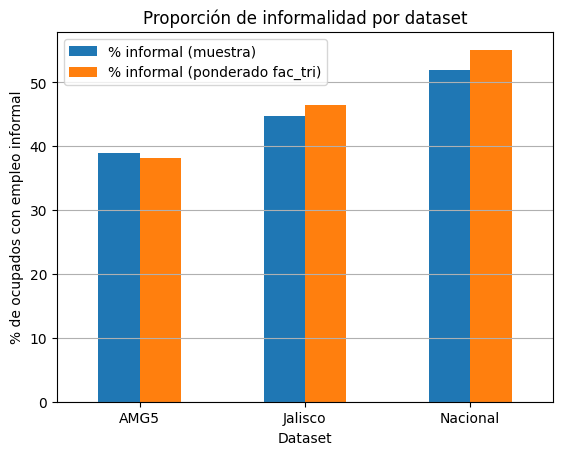

In [10]:
# Proporción de informales en la muestra (sin ponderar) y en la población (ponderada con fac_tri)
nombres = ["AMG5", "Jalisco", "Nacional"]
filas = []
informal_muestra = []
informal_ponderado = []
personas = []

for d in [df_amg5, df_jalisco, df_nacional]:
    filas.append(len(d))

    # muestra: promedio simple de y (cada persona cuenta igual)
    informal_muestra.append(round(100 * d["y"].mean(), 1))

    # población: cada persona pesa lo que indica su factor de expansión
    ponderado = (d["y"] * d["fac_tri"]).sum() / d["fac_tri"].sum()
    informal_ponderado.append(round(100 * ponderado, 1))

    # cuántas personas reales representa la muestra (en millones)
    personas.append(round(d["fac_tri"].sum() / 1000000, 2))

tabla_balance = pd.DataFrame({
    "Dataset": nombres,
    "Filas": filas,
    "% informal (muestra)": informal_muestra,
    "% informal (ponderado fac_tri)": informal_ponderado,
    "Personas representadas (millones)": personas
})
print(tabla_balance)

tabla_balance.plot.bar(x="Dataset", y=["% informal (muestra)", "% informal (ponderado fac_tri)"], rot=0)
plt.ylabel("% de ocupados con empleo informal")
plt.title("Proporción de informalidad por dataset")
plt.grid(axis="y")
plt.show()

#### Variables numéricas por condición de informalidad

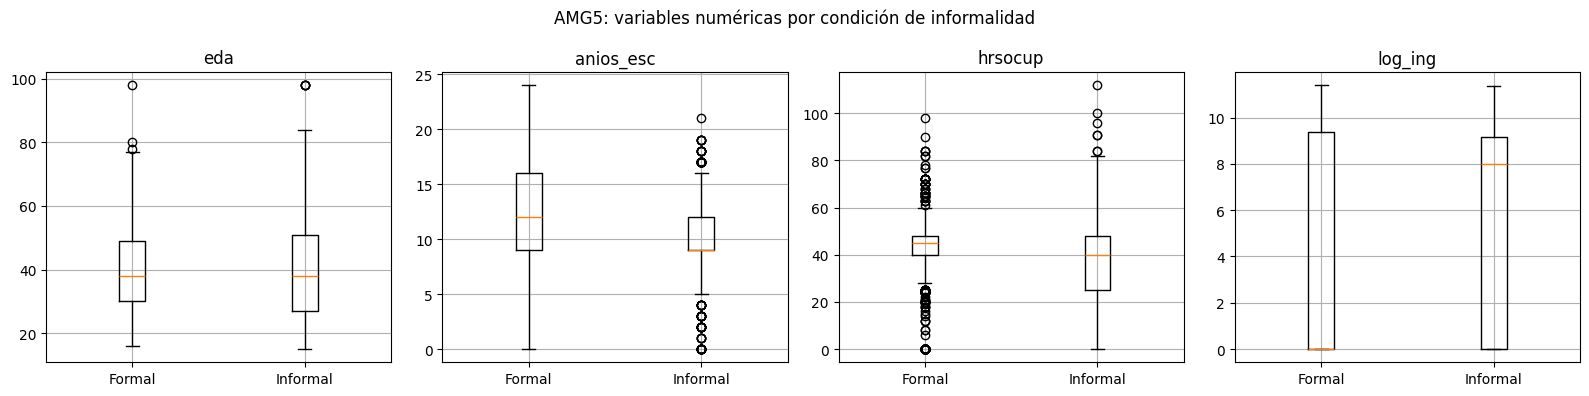

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

variables = ["eda", "anios_esc", "hrsocup", "log_ing"]
for i in range(4):
    var = variables[i]
    formal = df_amg5[df_amg5["y"] == 0][var]
    informal = df_amg5[df_amg5["y"] == 1][var]
    axes[i].boxplot([formal, informal])
    axes[i].set_xticks([1, 2])
    axes[i].set_xticklabels(["Formal", "Informal"])
    axes[i].set_title(var)
    axes[i].grid()

plt.suptitle("AMG5: variables numéricas por condición de informalidad")
plt.tight_layout()
plt.show()

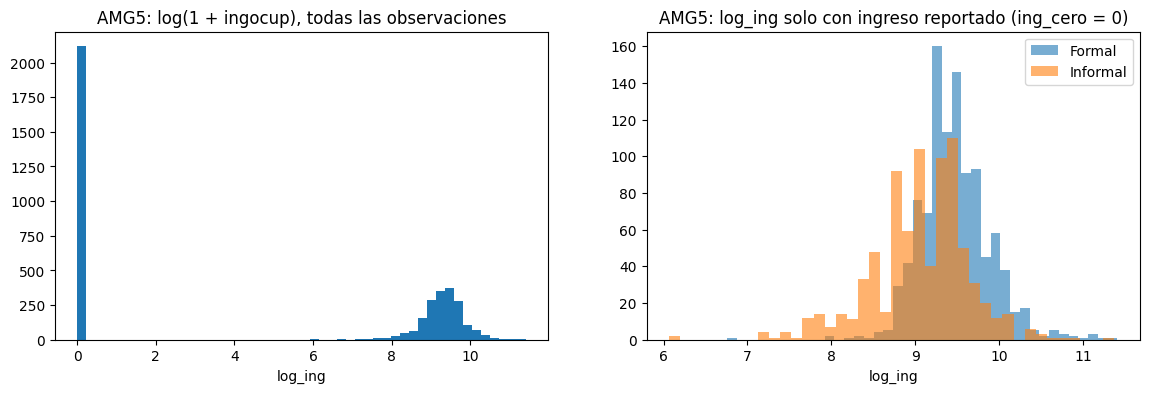

% de observaciones con ingocup = 0:
AMG5        53.5
Jalisco     47.7
Nacional    34.7
dtype: float64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df_amg5["log_ing"], bins=50)
axes[0].set_title("AMG5: log(1 + ingocup), todas las observaciones")
axes[0].set_xlabel("log_ing")

con_ingreso = df_amg5[df_amg5["ing_cero"] == 0]
axes[1].hist(con_ingreso[con_ingreso["y"] == 0]["log_ing"], bins=40, alpha=0.6, label="Formal")
axes[1].hist(con_ingreso[con_ingreso["y"] == 1]["log_ing"], bins=40, alpha=0.6, label="Informal")
axes[1].set_title("AMG5: log_ing solo con ingreso reportado (ing_cero = 0)")
axes[1].set_xlabel("log_ing")
axes[1].legend()
plt.show()

print("% de observaciones con ingocup = 0:")
print(pd.Series({"AMG5": df_amg5["ing_cero"].mean(), "Jalisco": df_jalisco["ing_cero"].mean(),
                 "Nacional": df_nacional["ing_cero"].mean()}).mul(100).round(1))

#### Tasa de informalidad por variable categórica

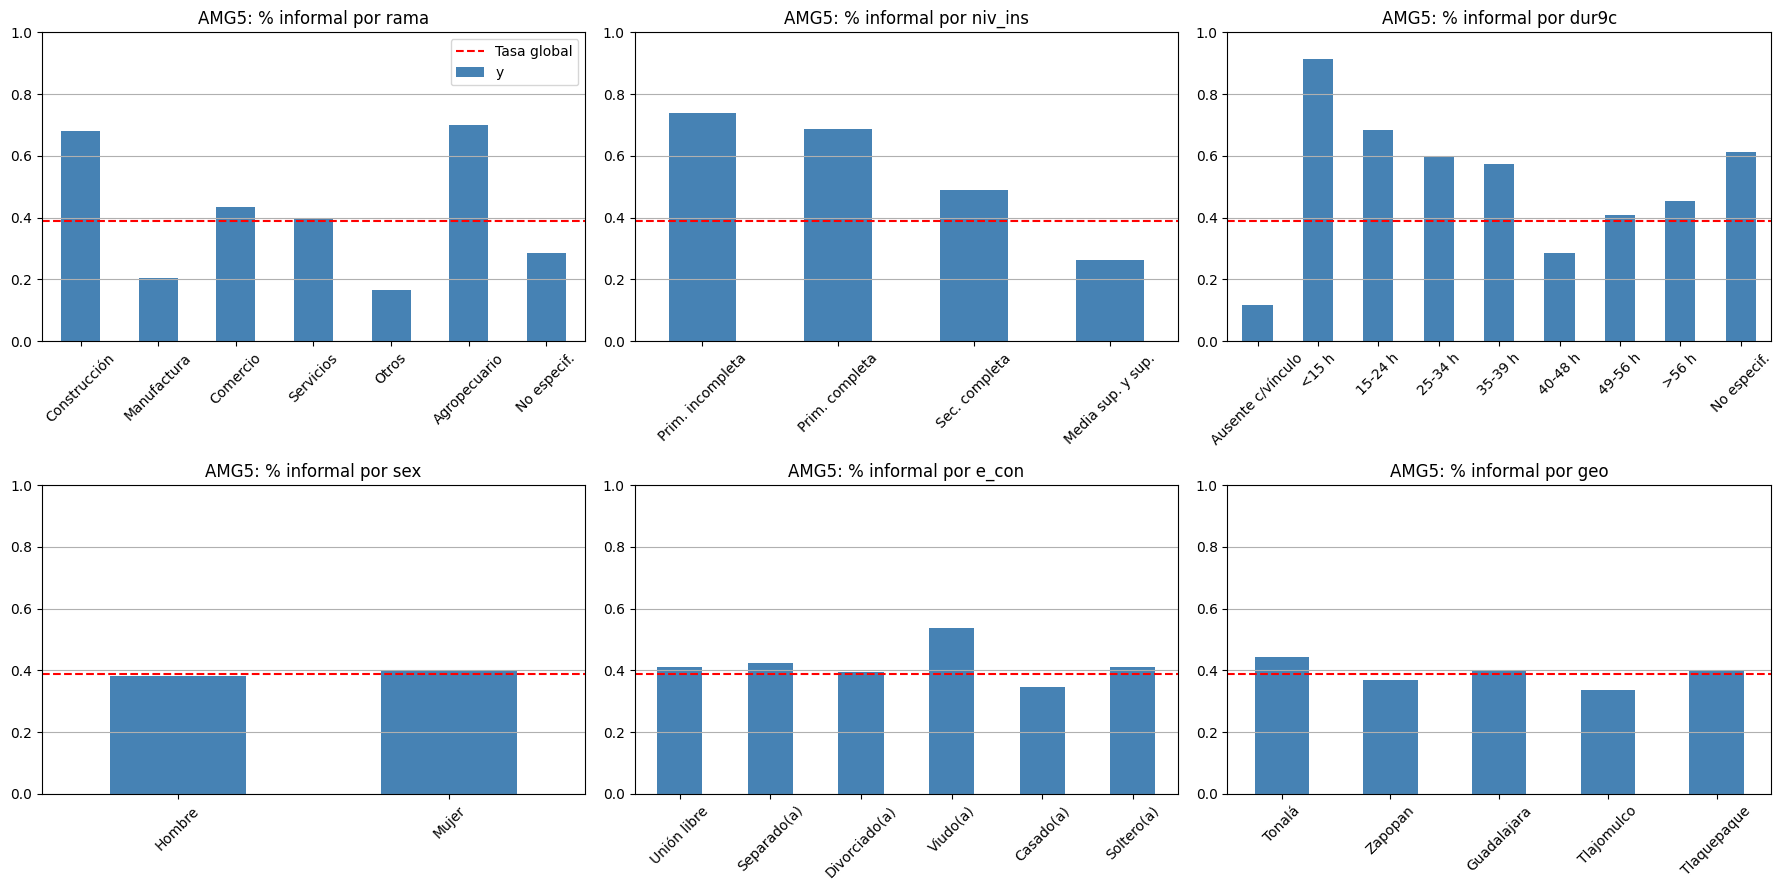

In [13]:
etiquetas = {
    "rama":    {"1": "Construcción", "2": "Manufactura", "3": "Comercio", "4": "Servicios",
                "5": "Otros", "6": "Agropecuario", "7": "No especif."},
    "niv_ins": {"1": "Prim. incompleta", "2": "Prim. completa", "3": "Sec. completa",
                "4": "Media sup. y sup.", "5": "No especif."},
    "dur9c":   {"1": "Ausente c/vínculo", "2": "<15 h", "3": "15-24 h", "4": "25-34 h", "5": "35-39 h",
                "6": "40-48 h", "7": "49-56 h", "8": ">56 h", "9": "No especif."},
    "sex":     {"1": "Hombre", "2": "Mujer"},
    "e_con":   {"1": "Unión libre", "2": "Separado(a)", "3": "Divorciado(a)", "4": "Viudo(a)",
                "5": "Casado(a)", "6": "Soltero(a)"},
    "geo":     {"39": "Guadalajara", "120": "Zapopan", "98": "Tlaquepaque", "101": "Tonalá", "97": "Tlajomulco"},
}

tasa_global = df_amg5["y"].mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, var in zip(axes.flat, ["rama", "niv_ins", "dur9c", "sex", "e_con", "geo"]):
    tasa = df_amg5.groupby(var)["y"].mean().sort_index()
    tasa.index = [etiquetas[var].get(i, i) for i in tasa.index]
    tasa.plot.bar(ax=ax, color="steelblue")
    ax.axhline(tasa_global, color="red", linestyle="--", label="Tasa global")
    ax.set_title(f"AMG5: % informal por {var}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

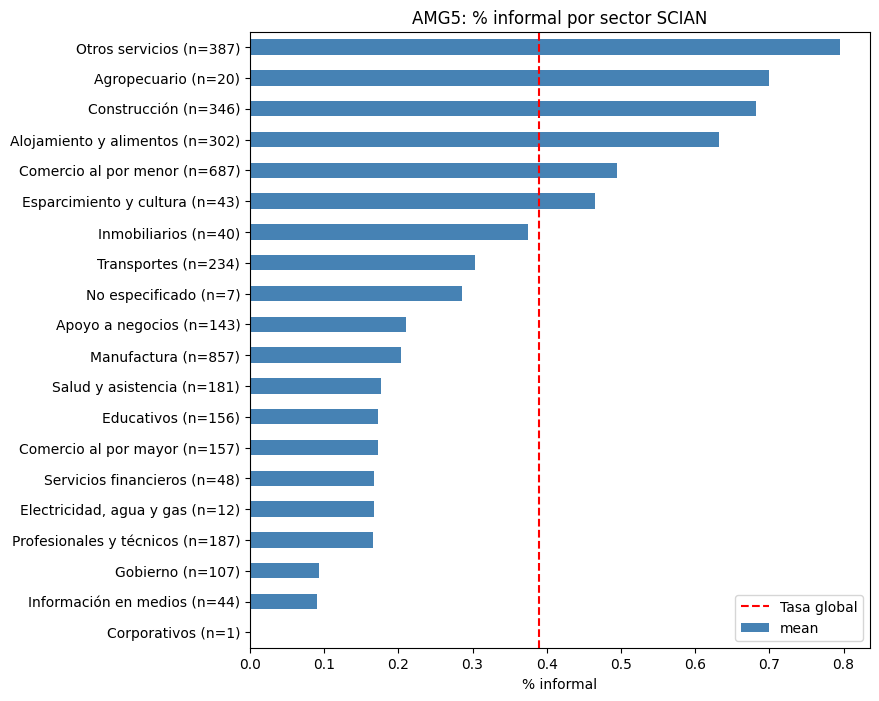

In [14]:
etiquetas_scian = {"1": "Agropecuario", "2": "Minería", "3": "Electricidad, agua y gas", "4": "Construcción",
                   "5": "Manufactura", "6": "Comercio al por mayor", "7": "Comercio al por menor",
                   "8": "Transportes", "9": "Información en medios", "10": "Servicios financieros",
                   "11": "Inmobiliarios", "12": "Profesionales y técnicos", "13": "Corporativos",
                   "14": "Apoyo a negocios", "15": "Educativos", "16": "Salud y asistencia",
                   "17": "Esparcimiento y cultura", "18": "Alojamiento y alimentos", "19": "Otros servicios",
                   "20": "Gobierno", "21": "No especificado"}

tasa_scian = df_amg5.groupby("scian")["y"].agg(["mean", "size"]).sort_values("mean")
tasa_scian.index = [etiquetas_scian.get(i, i) + f" (n={n})" for i, n in zip(tasa_scian.index, tasa_scian["size"])]
tasa_scian["mean"].plot.barh(figsize=(8, 8), color="steelblue")
plt.axvline(tasa_global, color="red", linestyle="--", label="Tasa global")
plt.xlabel("% informal")
plt.title("AMG5: % informal por sector SCIAN")
plt.legend()
plt.show()

#### Relación de la edad con la informalidad (¿forma de U?)

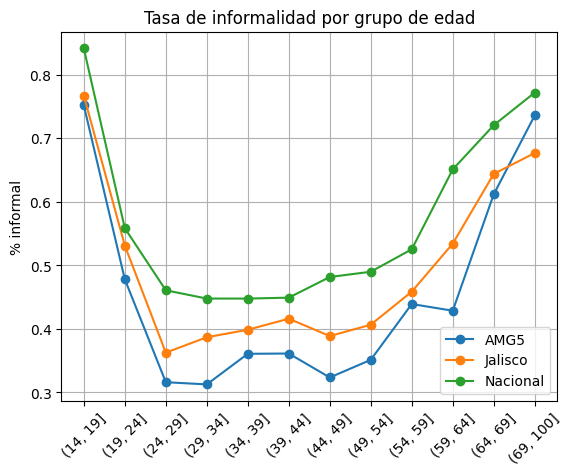

In [15]:
cortes = [14, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 100]
for nombre, d in [("AMG5", df_amg5), ("Jalisco", df_jalisco), ("Nacional", df_nacional)]:
    tasa_edad = d.groupby(pd.cut(d["eda"], bins=cortes), observed=True)["y"].mean()
    plt.plot([str(i) for i in tasa_edad.index], tasa_edad.values, marker="o", label=nombre)
plt.xticks(rotation=45)
plt.ylabel("% informal")
plt.title("Tasa de informalidad por grupo de edad")
plt.legend()
plt.grid()
plt.show()

Si la curva tiene forma de U, la regresión logística solo con `eda` lineal no captura bien el efecto. Por eso en la ablación se prueba agregar `eda2`. La SVM y el MLP pueden captar esta forma por sí mismos.

#### Correlación entre variables numéricas

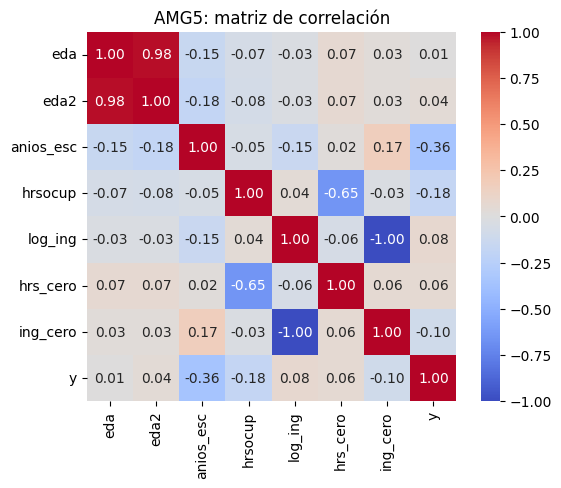

In [16]:
corr = df_amg5[["eda", "eda2", "anios_esc", "hrsocup", "log_ing", "hrs_cero", "ing_cero", "y"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("AMG5: matriz de correlación")
plt.show()

#### Informalidad por entidad federativa (nacional)

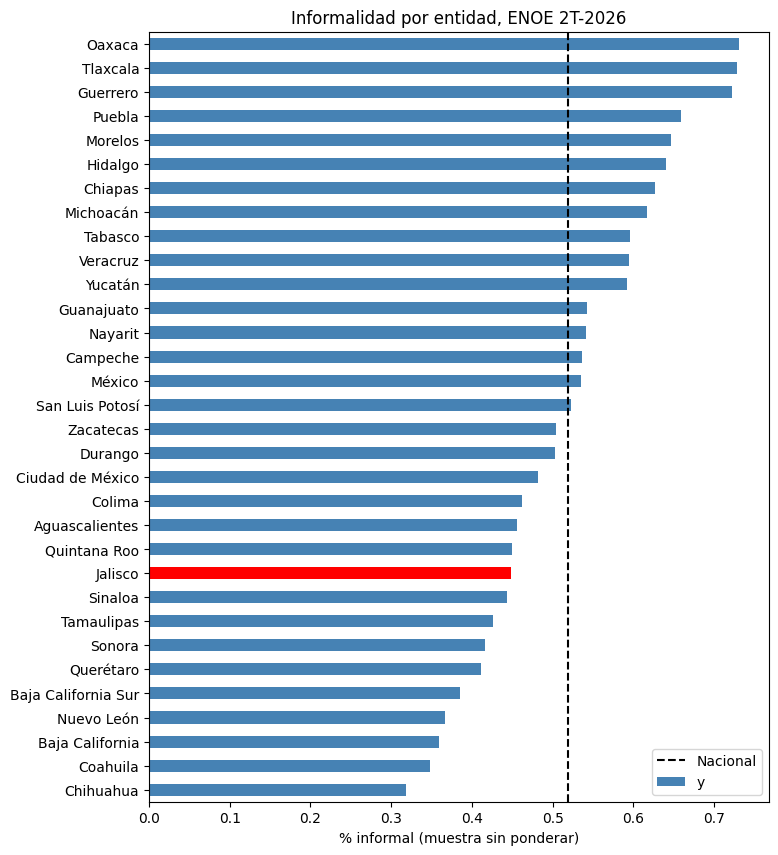

In [17]:
entidades = {1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur", 4: "Campeche", 5: "Coahuila",
             6: "Colima", 7: "Chiapas", 8: "Chihuahua", 9: "Ciudad de México", 10: "Durango", 11: "Guanajuato",
             12: "Guerrero", 13: "Hidalgo", 14: "Jalisco", 15: "México", 16: "Michoacán", 17: "Morelos",
             18: "Nayarit", 19: "Nuevo León", 20: "Oaxaca", 21: "Puebla", 22: "Querétaro", 23: "Quintana Roo",
             24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora", 27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala",
             30: "Veracruz", 31: "Yucatán", 32: "Zacatecas"}

tasa_ent = df_nacional.groupby("cve_ent")["y"].mean().sort_values()
tasa_ent.index = [entidades[int(i)] for i in tasa_ent.index]
tasa_ent.plot.barh(figsize=(8, 10), color=["red" if i == "Jalisco" else "steelblue" for i in tasa_ent.index])
plt.axvline(df_nacional["y"].mean(), color="black", linestyle="--", label="Nacional")
plt.xlabel("% informal (muestra sin ponderar)")
plt.title("Informalidad por entidad, ENOE 2T-2026")
plt.legend()
plt.show()

## 4. Modelo propuesto

Se comparan regresión logística con regularización elástica, SVM con kernel RBF y un perceptrón multicapa. Optuna busca los hiperparámetros que maximizan el ROC-AUC promedio en validación cruzada de cinco particiones del entrenamiento.

Se exploran `C` y `l1_ratio` para la regresión; `C` y `gamma` para la SVM; y número de capas, neuronas, `alpha` y tasa de aprendizaje para el MLP. Los rangos amplios se exploran en escala logarítmica.


## 5. Preprocesamiento y división de datos

Se dividen los datos en entrenamiento (80 %) y prueba (20 %), conservando la proporción de clases. El escalado y la codificación se hacen dentro de cada `Pipeline`, para ajustarlos solo con los datos de entrenamiento de cada partición de validación cruzada.


In [18]:
cat_modelo = ['sex', 'e_con', 'niv_ins', 'cs_p12', 'cs_p17', 't_loc_tri', 'ur', 'rama', 'dur9c', 'geo']
cv_opt = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
cv_final = StratifiedKFold(n_splits=10, shuffle=True, random_state=67)

def preprocesar(numericas, categoricas, binarias):
    return ColumnTransformer([
        ('num', StandardScaler(), numericas),
        ('bin', 'passthrough', binarias),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas)
    ])

x_amg = df_amg5[num + binarias + cat_modelo + ['scian', 'eda2']]
y_amg = df_amg5['y']
x_train_amg, x_test_amg, y_train_amg, y_test_amg = train_test_split(
    x_amg, y_amg, test_size=0.2, stratify=y_amg, random_state=67)

x_jal = df_jalisco[num + binarias + cat_modelo + ['scian', 'eda2']]
y_jal = df_jalisco['y']
x_train_jal, x_test_jal, y_train_jal, y_test_jal = train_test_split(
    x_jal, y_jal, test_size=0.2, stratify=y_jal, random_state=67)

x_nac = df_nacional[num + binarias + cat_modelo + ['scian', 'eda2']]
y_nac = df_nacional['y']
x_train_nac, x_test_nac, y_train_nac, y_test_nac = train_test_split(
    x_nac, y_nac, test_size=0.2, stratify=y_nac, random_state=67)


### 5.1 Selección de variables

Se comparan cinco variantes con regresión logística y validación cruzada en el entrenamiento de AMG5 y Jalisco: la configuración base, `scian` en lugar de `rama`, ambas variables, sin `ing_cero` y con edad al cuadrado. La selección final usa `scian`, conserva `ing_cero` y no incluye `eda2`.


In [19]:
variantes = {
    'Base': (num, binarias, cat_modelo),
    'Solo scian': (num, binarias, [c for c in cat_modelo if c != 'rama'] + ['scian']),
    'rama y scian': (num, binarias, cat_modelo + ['scian']),
    'Sin ing_cero': (num, ['hrs_cero'], cat_modelo),
    'Con eda2': (num + ['eda2'], binarias, cat_modelo)
}
resultados = []
for nombre, x_train, y_train in [('AMG5', x_train_amg, y_train_amg), ('Jalisco', x_train_jal, y_train_jal)]:
    for variante, (n, b, c) in variantes.items():
        modelo = Pipeline([('pre', preprocesar(n, c, b)), ('logistica', LogisticRegression(max_iter=2000))])
        scores = cross_val_score(modelo, x_train, y_train, cv=cv_final, scoring='roc_auc')
        resultados.append([nombre, variante, scores.mean(), scores.std()])

tabla_variables = pd.DataFrame(resultados, columns=['Dataset', 'Variante', 'AUC media', 'AUC std'])
display(tabla_variables)


,Dataset,Variante,AUC media,AUC std
0,AMG5,Base,0.801208,0.022532
1,AMG5,Solo scian,0.827800,0.021652
2,AMG5,rama y scian,0.827643,0.021680
3,AMG5,Sin ing_cero,0.797510,0.021486
4,AMG5,Con eda2,0.803950,0.022297
5,Jalisco,Base,0.820376,0.012613
6,Jalisco,Solo scian,0.844781,0.013172
7,Jalisco,rama y scian,0.844716,0.012931
8,Jalisco,Sin ing_cero,0.813530,0.013043
9,Jalisco,Con eda2,0.821448,0.011686


### 5.2 Variables seleccionadas

Se utiliza `scian` en lugar de `rama`, se conserva `ing_cero` y no se agrega `eda2`. La tabla anterior permite revisar esta decisión con los datos y las particiones de la ejecución actual.


In [20]:
cat_modelo.remove('rama')
cat_modelo.append('scian')
pre = preprocesar(num, cat_modelo, binarias)
print('Numéricas:', num)
print('Binarias:', binarias)
print('Categóricas:', cat_modelo)


Numéricas: ['eda', 'anios_esc', 'hrsocup', 'log_ing']
Binarias: ['hrs_cero', 'ing_cero']
Categóricas: ['sex', 'e_con', 'niv_ins', 'cs_p12', 'cs_p17', 't_loc_tri', 'ur', 'dur9c', 'geo', 'scian']


## 6. Ajuste de modelos y comparación

Para cada modelo se define una función objetivo que devuelve el ROC-AUC promedio de cinco particiones. Optuna elige los hiperparámetros; después se comparan los modelos con diez particiones y se evalúan en el conjunto de prueba. La SVM nacional usa una submuestra estratificada del entrenamiento por su costo computacional; el conjunto de prueba nacional es el mismo para los tres modelos.

Cada estudio usa 30 intentos. La ejecución completa, especialmente para el conjunto nacional, puede tardar varias horas.


In [21]:
def objetivo_logistica(trial):
    c = trial.suggest_float('C', 1e-4, 1e2, log=True)
    l1 = trial.suggest_float('l1_ratio', 0, 1)
    logistica = LogisticRegression(C=c, penalty='elasticnet', l1_ratio=l1,
                                   solver='saga', max_iter=3000, random_state=67)
    modelo = Pipeline([('pre', pre), ('modelo', logistica)])
    return cross_val_score(modelo, x_opt, y_opt, cv=cv_opt, scoring='roc_auc').mean()

def objetivo_svm(trial):
    c = trial.suggest_float('C', 1e-2, 1e3, log=True)
    gamma = trial.suggest_float('gamma', 1e-4, 1e1, log=True)
    svm = SVC(kernel='rbf', C=c, gamma=gamma)
    modelo = Pipeline([('pre', pre), ('modelo', svm)])
    return cross_val_score(modelo, x_opt, y_opt, cv=cv_opt, scoring='roc_auc').mean()

def objetivo_mlp(trial):
    capas = trial.suggest_int('n_capas', 1, 2)
    n1 = trial.suggest_int('neuronas_1', 5, 100)
    n2 = trial.suggest_int('neuronas_2', 5, 100)
    alpha = trial.suggest_float('alpha', 1e-5, 1, log=True)
    tasa = trial.suggest_float('learning_rate_init', 1e-4, 1e-1, log=True)
    if capas == 1:
        neuronas = (n1,)
    else:
        neuronas = (n1, n2)
    mlp = MLPClassifier(hidden_layer_sizes=neuronas, alpha=alpha, learning_rate_init=tasa,
                        early_stopping=True, max_iter=500, random_state=67)
    modelo = Pipeline([('pre', pre), ('modelo', mlp)])
    return cross_val_score(modelo, x_opt, y_opt, cv=cv_opt, scoring='roc_auc').mean()


In [22]:
# Para reducir el tiempo de la SVM nacional se toman hasta 30,000 personas del entrenamiento.
if len(y_train_nac) > 30000:
    x_svm_nac, _, y_svm_nac, _ = train_test_split(
        x_train_nac, y_train_nac, train_size=30000, stratify=y_train_nac, random_state=67)
else:
    x_svm_nac, y_svm_nac = x_train_nac, y_train_nac

conjuntos = {
    'AMG5': (x_train_amg, x_test_amg, y_train_amg, y_test_amg),
    'Jalisco': (x_train_jal, x_test_jal, y_train_jal, y_test_jal),
    'Nacional': (x_train_nac, x_test_nac, y_train_nac, y_test_nac)
}
objetivos = {'Logística': objetivo_logistica, 'SVM': objetivo_svm, 'MLP': objetivo_mlp}
estudios = {}
for nombre, (x_train, x_test, y_train, y_test) in conjuntos.items():
    estudios[nombre] = {}
    for modelo, objetivo in objetivos.items():
        x_opt, y_opt = x_train, y_train
        if nombre == 'Nacional' and modelo == 'SVM':
            x_opt, y_opt = x_svm_nac, y_svm_nac
        print(nombre, '-', modelo, '| observaciones:', len(y_opt))
        estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=67))
        estudio.optimize(objetivo, n_trials=30)
        estudios[nombre][modelo] = estudio
        print('Mejores parámetros:', estudio.best_params)
        print('Mejor AUC:', estudio.best_value)


AMG5

[I 2026-11-02 01:40:37,649] A new study created in memory with name: no-name-9fd822c9-aeae-42ed-85d7-11e0c4faaa37


 - Logística | observaciones: 3167


c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in ve

Mejores parámetros: {'C': 1.7049802911574319, 'l1_ratio': 0.9722181727486503}
Mejor AUC: 0.8284502148522762
AMG5 - SVM | observaciones: 3167


[I 2026-11-02 01:41:22,492] Trial 0 finished with value: 0.6996122200176046 and parameters: {'C': 5.361140014825926, 'gamma': 1.9691692845736382}. Best is trial 0 with value: 0.6996122200176046.
[I 2026-11-02 01:41:24,969] Trial 1 finished with value: 0.8290171099324837 and parameters: {'C': 26.882083938628128, 'gamma': 0.004549452186429166}. Best is trial 1 with value: 0.8290171099324837.
[I 2026-11-02 01:41:28,602] Trial 2 finished with value: 0.7810841429226403 and parameters: {'C': 0.019952147548384695, 'gamma': 0.008538643965272543}. Best is trial 1 with value: 0.8290171099324837.
[I 2026-11-02 01:41:33,547] Trial 3 finished with value: 0.6831144564885936 and parameters: {'C': 0.11634542045495928, 'gamma': 4.5976218744590405}. Best is trial 1 with value: 0.8290171099324837.
[I 2026-11-02 01:41:36,652] Trial 4 finished with value: 0.8198901199459444 and parameters: {'C': 41.12363485239494, 'gamma': 0.00017158389940111508}. Best is trial 1 with value: 0.8290171099324837.
[I 2026-11-

... (11 outputs left out)

[I 2026-11-02 02:29:37,082] Trial 0 finished with value: 0.7725273058999037 and parameters: {'C': 5.361140014825926, 'gamma': 1.9691692845736382}. Best is trial 0 with value: 0.7725273058999037.
[I 2026-11-02 02:32:33,691] Trial 1 finished with value: 0.8826392159979346 and parameters: {'C': 26.882083938628128, 'gamma': 0.004549452186429166}. Best is trial 1 with value: 0.8826392159979346.
[I 2026-11-02 02:36:39,194] Trial 2 finished with value: 0.8210345318669819 and parameters: {'C': 0.019952147548384695, 'gamma': 0.008538643965272543}. Best is trial 1 with value: 0.8826392159979346.
[I 2026-11-02 02:47:23,956] Trial 3 finished with value: 0.7484983982859251 and parameters: {'C': 0.11634542045495928, 'gamma': 4.5976218744590405}. Best is trial 1 with value: 0.8826392159979346.
[I 2026-11-02 02:50:13,393] Trial 4 finished with value: 0.8662827076628785 and parameters: {'C': 41.12363485239494, 'gamma': 0.00017158389940111508}. Best is trial 1 with value: 0.8826392159979346.
[I 2026-11-

Mejores parámetros: {'C': 8.575686488018977, 'gamma': 0.01614072024897502}
Mejor AUC: 0.8842353650662874
Nacional - MLP | observaciones: 150938


[I 2026-11-02 10:35:48,527] Trial 0 finished with value: 0.8905745632065916 and parameters: {'n_capas': 2, 'neuronas_1': 87, 'neuronas_2': 70, 'alpha': 0.0004549452186429169, 'learning_rate_init': 0.00015135396015039752}. Best is trial 0 with value: 0.8905745632065916.
[I 2026-11-02 10:39:27,065] Trial 1 finished with value: 0.886712176008621 and parameters: {'n_capas': 1, 'neuronas_1': 25, 'neuronas_2': 94, 'alpha': 0.04112363485239492, 'learning_rate_init': 0.00013825661511434535}. Best is trial 0 with value: 0.8905745632065916.
[I 2026-11-02 10:41:05,447] Trial 2 finished with value: 0.8911037336283526 and parameters: {'n_capas': 2, 'neuronas_1': 61, 'neuronas_2': 29, 'alpha': 0.0003761693892248827, 'learning_rate_init': 0.00036602779598880964}. Best is trial 2 with value: 0.8911037336283526.
[I 2026-11-02 10:41:38,130] Trial 3 finished with value: 0.8900121621442182 and parameters: {'n_capas': 1, 'neuronas_1': 29, 'neuronas_2': 6, 'alpha': 0.0011167155132661363, 'learning_rate_init

Mejores parámetros: {'n_capas': 1, 'neuronas_1': 88, 'neuronas_2': 18, 'alpha': 0.03484537099930845, 'learning_rate_init': 0.0003081581171506648}
Mejor AUC: 0.8923517628094739


### 6.1 Convergencia de la optimización

La línea muestra el mejor ROC-AUC encontrado hasta cada intento de Optuna.


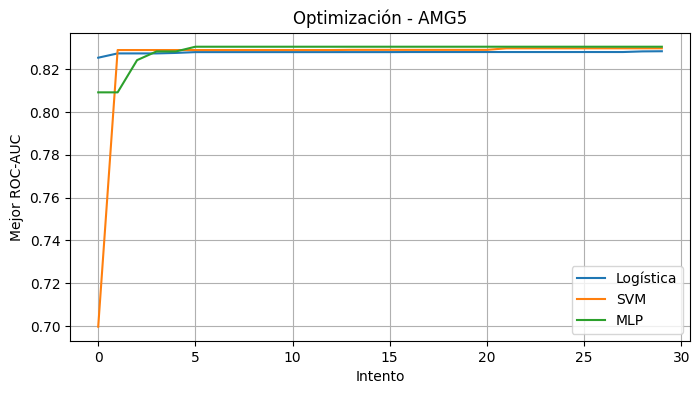

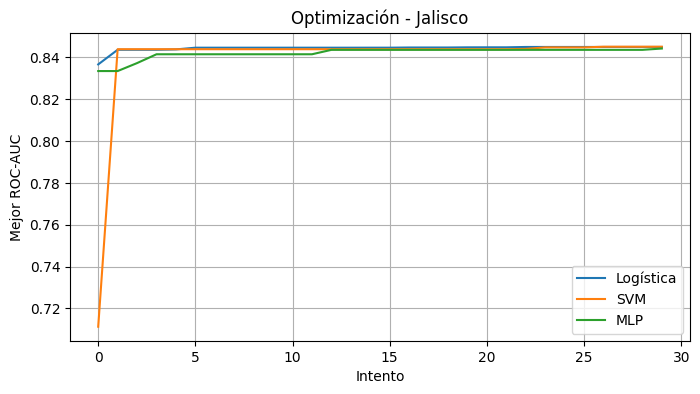

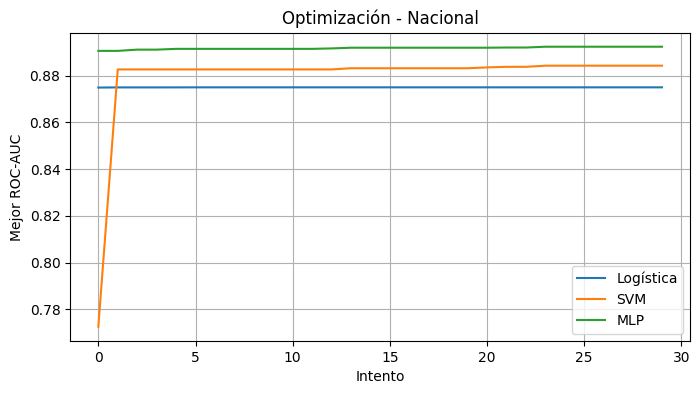

In [23]:
for nombre in estudios:
    plt.figure(figsize=(8, 4))
    for modelo, estudio in estudios[nombre].items():
        valores = [t.value for t in estudio.trials]
        plt.plot(np.maximum.accumulate(valores), label=modelo)
    plt.title('Optimización - ' + nombre)
    plt.xlabel('Intento')
    plt.ylabel('Mejor ROC-AUC')
    plt.legend()
    plt.grid()
    plt.show()


### 6.2 Validación cruzada y evaluación en prueba

Se ajusta cada modelo con los mejores parámetros encontrados. Se muestran el promedio y la desviación estándar del ROC-AUC de diez particiones de entrenamiento, además de las métricas y matrices de confusión en prueba. En el conjunto nacional la validación cruzada de la SVM usa la submuestra; por eso su puntuación de validación no se obtiene sobre exactamente las mismas personas que la de los otros modelos.


c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in ve

AMG5 - Logística 
 [[435  48]
 [111 198]]
AMG5 - SVM 
 [[436  47]
 [110 199]]
AMG5 - MLP 
 [[406  77]
 [ 96 213]]


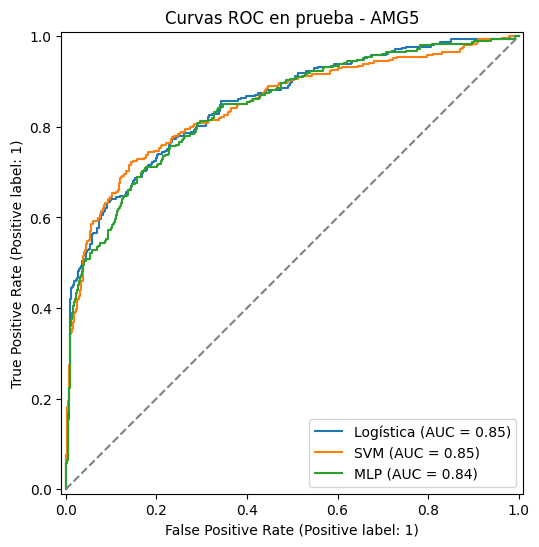

c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in ve

Jalisco - Logística 
 [[533 117]
 [153 374]]
Jalisco - SVM 
 [[551  99]
 [156 371]]
Jalisco - MLP 
 [[545 105]
 [158 369]]


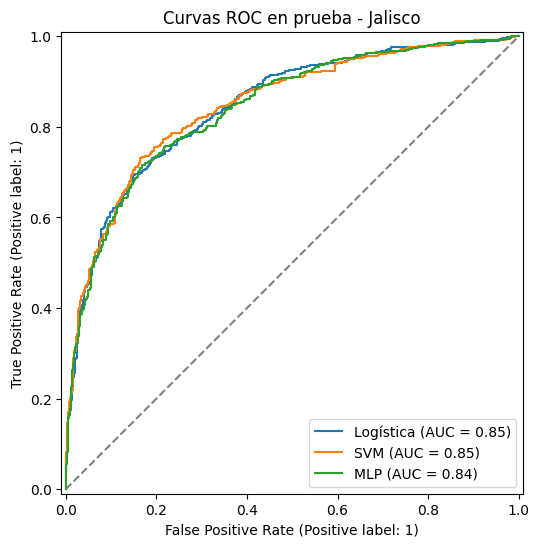

c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in ve

Nacional - Logística 
 [[14526  3615]
 [ 4063 15531]]
Nacional - SVM 
 [[14942  3199]
 [ 4120 15474]]
Nacional - MLP 
 [[14868  3273]
 [ 3794 15800]]


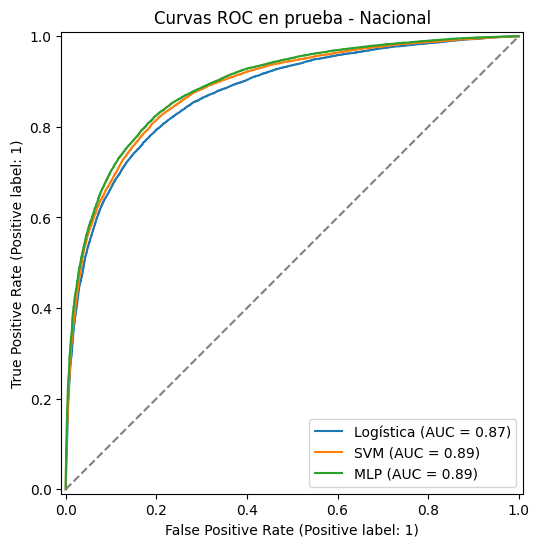

,Dataset,Modelo,n,AUC media,AUC std,Accuracy,Precision,Recall,F1
0,AMG5,Logística,3167,0.8293,0.0216,0.7686,0.7332,0.6385,0.6819
1,AMG5,SVM,3167,0.8310,0.0231,0.7764,0.7671,0.6158,0.6816
2,AMG5,MLP,3167,0.8312,0.0211,0.7695,0.7400,0.6345,0.6809
3,Jalisco,Logística,4705,0.8463,0.0121,0.7743,0.7692,0.7091,0.7375
4,Jalisco,SVM,4705,0.8454,0.0110,0.7764,0.7759,0.7048,0.7383
5,Jalisco,MLP,4705,0.8398,0.0128,0.7632,0.7721,0.6735,0.7175
6,Nacional,Logística,150938,0.8750,0.0024,0.7967,0.8107,0.7939,0.8022
7,Nacional,SVM,30000,0.8848,0.0047,0.8059,0.8273,0.7916,0.8090
8,Nacional,MLP,150938,0.8922,0.0023,0.8125,0.8294,0.8044,0.8167


,Dataset,Modelo,ROC-AUC,Accuracy,Precision,Recall,F1
0,AMG5,Logística,0.8508,0.7992,0.8049,0.6408,0.7135
1,AMG5,SVM,0.8468,0.8018,0.8089,0.6440,0.7171
2,AMG5,MLP,0.8426,0.7816,0.7345,0.6893,0.7112
3,Jalisco,Logística,0.8457,0.7706,0.7617,0.7097,0.7348
4,Jalisco,SVM,0.8469,0.7833,0.7894,0.7040,0.7442
5,Jalisco,MLP,0.8413,0.7766,0.7785,0.7002,0.7373
6,Nacional,Logística,0.8748,0.7965,0.8112,0.7926,0.8018
7,Nacional,SVM,0.8859,0.8060,0.8287,0.7897,0.8087
8,Nacional,MLP,0.8928,0.8127,0.8284,0.8064,0.8172


In [24]:
resultados_cv = []
resultados_test = []
for nombre, (x_train, x_test, y_train, y_test) in conjuntos.items():
    fig, ax = plt.subplots(figsize=(6, 6))
    for tipo, estudio in estudios[nombre].items():
        p = estudio.best_params
        if tipo == 'Logística':
            clasificador = LogisticRegression(C=p['C'], penalty='elasticnet', l1_ratio=p['l1_ratio'],
                                               solver='saga', max_iter=3000, random_state=67)
        elif tipo == 'SVM':
            clasificador = SVC(kernel='rbf', C=p['C'], gamma=p['gamma'])
        else:
            if p['n_capas'] == 1:
                neuronas = (p['neuronas_1'],)
            else:
                neuronas = (p['neuronas_1'], p['neuronas_2'])
            clasificador = MLPClassifier(hidden_layer_sizes=neuronas, alpha=p['alpha'],
                                          learning_rate_init=p['learning_rate_init'],
                                          early_stopping=True, max_iter=500, random_state=67)
        modelo = Pipeline([('pre', pre), ('modelo', clasificador)])
        x_ajuste, y_ajuste = x_train, y_train
        if nombre == 'Nacional' and tipo == 'SVM':
            x_ajuste, y_ajuste = x_svm_nac, y_svm_nac
        scores = cross_validate(modelo, x_ajuste, y_ajuste, cv=cv_final,
                                scoring=['roc_auc', 'accuracy', 'precision', 'recall', 'f1'])
        resultados_cv.append([nombre, tipo, len(y_ajuste), scores['test_roc_auc'].mean(),
                              scores['test_roc_auc'].std(), scores['test_accuracy'].mean(),
                              scores['test_precision'].mean(), scores['test_recall'].mean(), scores['test_f1'].mean()])
        modelo.fit(x_ajuste, y_ajuste)
        pred = modelo.predict(x_test)
        if tipo == 'MLP':
            puntaje = modelo.predict_proba(x_test)[:, 1]
        else:
            puntaje = modelo.decision_function(x_test)
        resultados_test.append([nombre, tipo, roc_auc_score(y_test, puntaje), accuracy_score(y_test, pred),
                                precision_score(y_test, pred, zero_division=0), recall_score(y_test, pred, zero_division=0),
                                f1_score(y_test, pred, zero_division=0)])
        RocCurveDisplay.from_estimator(modelo, x_test, y_test, name=tipo, ax=ax)
        print(nombre, '-', tipo, '\n', confusion_matrix(y_test, pred))
    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set_title('Curvas ROC en prueba - ' + nombre)
    plt.show()

tabla_cv = pd.DataFrame(resultados_cv, columns=['Dataset', 'Modelo', 'n', 'AUC media', 'AUC std', 'Accuracy', 'Precision', 'Recall', 'F1'])
tabla_test = pd.DataFrame(resultados_test, columns=['Dataset', 'Modelo', 'ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1'])
display(tabla_cv.round(4))
display(tabla_test.round(4))


### 6.3 Comparación entre conjuntos de datos


In [25]:
display(tabla_cv.pivot(index='Modelo', columns='Dataset', values='AUC media').round(4))
display(tabla_test.pivot(index='Modelo', columns='Dataset', values='ROC-AUC').round(4))

for nombre in estudios:
    for modelo, estudio in estudios[nombre].items():
        print(nombre, '-', modelo, ':', estudio.best_params)


Dataset,AMG5,Jalisco,Nacional
Modelo,,,
Logística,0.8293,0.8463,0.8750
MLP,0.8312,0.8398,0.8922
SVM,0.8310,0.8454,0.8848


Dataset,AMG5,Jalisco,Nacional
Modelo,,,
Logística,0.8508,0.8457,0.8748
MLP,0.8426,0.8413,0.8928
SVM,0.8468,0.8469,0.8859


AMG5 - Logística : {'C': 1.7049802911574319, 'l1_ratio': 0.9722181727486503}
AMG5 - SVM : {'C': 36.603420168020364, 'gamma': 0.010493127435564104}
AMG5 - MLP : {'n_capas': 1, 'neuronas_1': 57, 'neuronas_2': 73, 'alpha': 0.5849554154655763, 'learning_rate_init': 0.006394026351091502}
Jalisco - Logística : {'C': 4.380191391289973, 'l1_ratio': 0.9677617966765195}
Jalisco - SVM : {'C': 276.0576269287339, 'gamma': 0.0020190962859362245}
Jalisco - MLP : {'n_capas': 1, 'neuronas_1': 24, 'neuronas_2': 45, 'alpha': 0.350460604596511, 'learning_rate_init': 0.0062982300198773985}
Nacional - Logística : {'C': 91.67633272139, 'l1_ratio': 0.9905368081524026}
Nacional - SVM : {'C': 8.575686488018977, 'gamma': 0.01614072024897502}
Nacional - MLP : {'n_capas': 1, 'neuronas_1': 88, 'neuronas_2': 18, 'alpha': 0.03484537099930845, 'learning_rate_init': 0.0003081581171506648}


## 7. Conclusiones



## 8. Referencias

- Abe, S. (2010). *Support vector machines for pattern classification* (2nd ed.). Springer-Verlag London. https://doi.org/10.1007/978-1-84996-098-4
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701
- Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. *Pattern Recognition, 30*(7), 1145–1159. https://doi.org/10.1016/S0031-3203(96)00142-2
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.
- Instituto Nacional de Estadística y Geografía. (2014). *La informalidad laboral. Encuesta Nacional de Ocupación y Empleo: Marco conceptual y metodológico*. INEGI.
- Instituto Nacional de Estadística y Geografía. (2026). *Encuesta Nacional de Ocupación y Empleo (ENOE), población de 15 años y más de edad: Microdatos, segundo trimestre de 2026* [Conjunto de datos]. INEGI. https://www.inegi.org.mx/programas/enoe/15ymas/
- Instituto Nacional de Estadística y Geografía. (s. f.). *Encuesta Nacional de Ocupación y Empleo: Descriptor de archivos y diccionario de datos*. INEGI.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. En *3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
- Organización Internacional del Trabajo. (2013). *La medición de la informalidad: Manual estadístico sobre el sector informal y el empleo informal*. OIT.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. En *Advances in Neural Information Processing Systems 25* (pp. 2951–2959).
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B (Statistical Methodology), 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x